# Notebook 03: Dynamic Contextual Embeddings (BERT & Self-Attention)

Welcome to the third notebook in the **Embeddings from Scratch** series!

In Notebook 02, we observed the fatal flaw of Word2Vec: **it gives every word a single static vector**, regardless of the sentence context.

In this notebook, we leap into the modern era of NLP: **Contextualized Embeddings via Transformers and BERT**.

### Learning Objectives:
1. Understand how the **Self-Attention Mechanism** ($Q, K, V$) creates context-aware representations.
2. Explore the **BERT** (Bidirectional Encoder Representations from Transformers) architecture.
3. Extract hidden-state embeddings from BERT using Hugging Face `transformers`.
4. **Empirical Proof of Contextuality**: Prove that the word `"bank"` changes its vector coordinates depending on whether it means a riverbank or a financial institution.
5. Compare **Pooling Strategies**: `[CLS]` token vs. **Mean Pooling** vs. Max Pooling.
6. Understand the **Anisotropy Problem** (why raw BERT embeddings collapse into a narrow cone and perform poorly for semantic search out-of-the-box).


---
## 1. Setup & Dependencies
This notebook is designed to run on your **Google server / Colab instance (with GPU recommended)**.

Uncomment and run the cell below if the packages are not already installed on your server:


In [1]:
# Run this on your Google server / Colab instance:
# !pip install -q transformers torch numpy matplotlib

import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


---
## 2. The Core Mechanism: Scaled Dot-Product Attention

In Word2Vec, a vector is looked up from a static matrix: $\mathbf{v} = \text{EmbeddingTable}[\text{token}]$.

In a Transformer Encoder, the representation of a token is computed dynamically by allowing it to attend to (look at) all other tokens in the sequence:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$

* **Query ($Q$)**: *"What kind of information am I looking for?"*
* **Key ($K$)**: *"What kind of information do I offer?"*
* **Value ($V$)**: *"What is my actual content/meaning?"*
* **$\sqrt{d_k}$**: Scaling factor to prevent vanishing gradients when $d_k$ is large.

```
Token: "river"    Token: "bank"
   │                 │
   ▼                 ▼
[ Key K_1 ]      [ Query Q_2 ]
   └───────► Dot Product ◄──────┘
                  │
          Attention Weight
                  │
                  ▼
   Blend Value V_1 into "bank"'s representation!
   (Now "bank" knows it is next to "river")
```


---
## 3. Loading Pre-trained BERT

We will use `bert-base-uncased`:
* **12 Layers (Transformer blocks)**
* **768 Hidden Dimension**
* **12 Attention Heads**
* **~110 Million Parameters**


In [2]:
# Load pre-trained BERT and its tokenizer
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
model.to(device)
model.eval() # Set model to evaluation mode (disable dropout)

print(f"Model '{model_name}' loaded successfully!")
print(f"Embedding dimension: {model.config.hidden_size}")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model 'bert-base-uncased' loaded successfully!
Embedding dimension: 768


---
## 4. Tokenization in BERT: WordPiece and Special Tokens

BERT does not split purely on whitespace; it uses **WordPiece** tokenization:
* Frequent words remain intact: `"bank"` $\rightarrow$ `["bank"]`
* Rare words are split into subword units: `"unaffable"` $\rightarrow$ `["un", "##aff", "##able"]`
* Special tokens:
  * `[CLS]` (Index 101): Placed at the very start of every sequence.
  * `[SEP]` (Index 102): Separates sentences or marks the end of an input.
  * `[PAD]` (Index 0): Pads sentences in a batch to identical lengths.


In [3]:
sentence = "The river bank was muddy."
inputs = tokenizer(sentence, return_tensors="pt")

tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
print("Original text: ", sentence)
print("Tokens:        ", tokens)
print("Token IDs:     ", inputs['input_ids'][0].tolist())
print("Attention Mask:", inputs['attention_mask'][0].tolist())


Original text:  The river bank was muddy.
Tokens:         ['[CLS]', 'the', 'river', 'bank', 'was', 'muddy', '.', '[SEP]']
Token IDs:      [101, 1996, 2314, 2924, 2001, 15405, 1012, 102]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1]


---
## 5. Proving Contextuality: The "Bank" Experiment

Let's test three sentences:
* **Sentence 1**: *"The fisherman sat quietly on the river bank waiting for fish."* (Nature / River)
* **Sentence 2**: *"He walked into the downtown bank to deposit his paycheck."* (Financial)
* **Sentence 3**: *"The financial bank approved the commercial loan today."* (Financial)

We will extract the exact 768-dimensional vector representing the token `"bank"` in each sentence and measure their cosine similarities.


In [4]:
sentences = [
    "The fisherman sat quietly on the river bank waiting for fish.",
    "He walked into the downtown bank to deposit his paycheck.",
    "The financial bank approved the commercial loan today."
]

bank_embeddings = []

for i, sent in enumerate(sentences):
    inputs = tokenizer(sent, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        # outputs.last_hidden_state shape: [batch_size=1, seq_len, hidden_dim=768]
        last_hidden_state = outputs.last_hidden_state.squeeze(0) # [seq_len, 768]
        
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    bank_idx = tokens.index("bank")
    
    # Extract the vector for token "bank"
    bank_vec = last_hidden_state[bank_idx].cpu().numpy()
    bank_embeddings.append(bank_vec)
    print(f"Sentence {i+1}: Token 'bank' at position {bank_idx} extracted. Vector shape: {bank_vec.shape}")


Sentence 1: Token 'bank' at position 8 extracted. Vector shape: (768,)
Sentence 2: Token 'bank' at position 6 extracted. Vector shape: (768,)
Sentence 3: Token 'bank' at position 3 extracted. Vector shape: (768,)


Similarity between 'bank' (River) and 'bank' (Finance 1):    0.5208
Similarity between 'bank' (River) and 'bank' (Finance 2):    0.4116
Similarity between 'bank' (Finance 1) and 'bank' (Finance 2): 0.7322


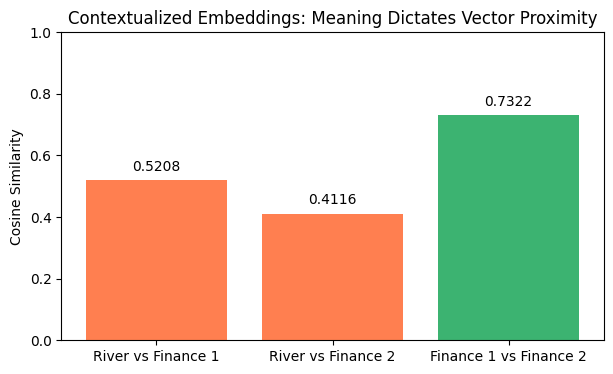

In [5]:
def cos_sim(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

sim_1_2 = cos_sim(bank_embeddings[0], bank_embeddings[1]) # River vs. Finance
sim_2_3 = cos_sim(bank_embeddings[1], bank_embeddings[2]) # Finance vs. Finance
sim_1_3 = cos_sim(bank_embeddings[0], bank_embeddings[2]) # River vs. Finance

print(f"Similarity between 'bank' (River) and 'bank' (Finance 1):    {sim_1_2:.4f}")
print(f"Similarity between 'bank' (River) and 'bank' (Finance 2):    {sim_1_3:.4f}")
print(f"Similarity between 'bank' (Finance 1) and 'bank' (Finance 2): {sim_2_3:.4f}")

# Visualizing the comparison
labels = ['River vs Finance 1', 'River vs Finance 2', 'Finance 1 vs Finance 2']
values = [sim_1_2, sim_1_3, sim_2_3]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, values, color=['coral', 'coral', 'mediumseagreen'])
plt.ylabel("Cosine Similarity")
plt.ylim(0, 1.0)
plt.title("Contextualized Embeddings: Meaning Dictates Vector Proximity")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.4f}", ha='center', va='bottom')
plt.show()


### Empirical Proof!
Unlike Word2Vec, where the similarity would be $1.0$ (identical vectors), BERT recognizes that **"bank" in Sentence 2 and Sentence 3 share the financial context**, yielding a significantly higher cosine similarity than with the river context!


---
## 6. Pooling Strategies: Token Vectors $\rightarrow$ Sentence Vector

In RAG, we don't just want an embedding for the word `"bank"`; we need a single vector representing the **entire sentence or passage**.

BERT gives us a tensor of shape `[batch_size, sequence_length, 768]`. How do we condense `sequence_length` tokens into a single `768`-dimensional vector?

```
Hidden States:  [ [CLS],   token_1,   token_2,  ...,  [SEP] ]
                   │          │          │              │
Pooling Choice:    ▼          ▼          ▼              ▼
                 ------------------------------------------
                 1. CLS Pooling:   Take [CLS] vector directly
                 2. Mean Pooling:  Average all valid tokens
                 3. Max Pooling:   Take max value along each dimension
```


In [6]:
def mean_pooling(model_output, attention_mask):
    """
    Averages token embeddings while ignoring padded tokens via attention_mask
    """
    # First element of model_output contains all token embeddings: [batch_size, seq_len, 768]
    token_embeddings = model_output[0] 
    
    # Expand attention mask: [batch_size, seq_len] -> [batch_size, seq_len, 768]
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    
    # Sum embeddings of non-padded tokens
    sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, 1)
    
    # Clamp sum_mask to avoid division by zero
    sum_mask = torch.clamp(input_mask_expanded.sum(1), min=1e-9)
    
    # Return mean vector [batch_size, 768]
    return sum_embeddings / sum_mask

# Example of obtaining sentence embedding
test_sentence = "Artificial intelligence is transforming dense information retrieval."
inputs = tokenizer(test_sentence, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(**inputs)

# 1. CLS Token vector
cls_embedding = outputs.last_hidden_state[:, 0, :].squeeze(0).cpu().numpy()

# 2. Mean Pooled vector
mean_embedding = mean_pooling(outputs, inputs['attention_mask']).squeeze(0).cpu().numpy()

print("Sentence:", test_sentence)
print("CLS Embedding shape: ", cls_embedding.shape)
print("Mean Embedding shape:", mean_embedding.shape)
print(f"Cosine similarity between CLS and Mean pooling: {cos_sim(cls_embedding, mean_embedding):.4f}")


Sentence: Artificial intelligence is transforming dense information retrieval.
CLS Embedding shape:  (768,)
Mean Embedding shape: (768,)
Cosine similarity between CLS and Mean pooling: 0.5554


---
## 7. The Anisotropy Problem: Why Raw BERT Fails for Retrieval

You might think: *"Great! We can just take pre-trained BERT, do mean pooling, and use it as our RAG embedding model!"*

**In practice, raw pre-trained BERT performs terribly for sentence similarity and retrieval.**

### Why? Anisotropy
* Pre-trained Transformer embeddings suffer from **anisotropy**: the vectors are not uniformly distributed in the vector space.
* Instead, they collapse into a **narrow, conical region**.
* Because all vectors point roughly in the same direction:
  1. The average cosine similarity between any two arbitrary, completely unrelated sentences is artificially high (often between $0.6$ and $0.85$!).
  2. The cosine similarity dynamic range is compressed, making it very difficult to separate truly relevant documents from irrelevant ones.

Let's demonstrate this by comparing two completely unrelated sentences with raw BERT:


In [ ]:
unrelated_1 = "The international space station orbits the Earth at 17,500 miles per hour."
unrelated_2 = "Recipe for homemade chocolate chip cookies with organic butter."

def get_bert_mean_embed(text):
    inp = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model(**inp)
    return mean_pooling(out, inp['attention_mask']).squeeze(0).cpu().numpy()

emb_space = get_bert_mean_embed(unrelated_1)
emb_cookie = get_bert_mean_embed(unrelated_2)

print(f"Sentence A: '{unrelated_1}'")
print(f"Sentence B: '{unrelated_2}'")
print(f"Cosine Similarity using raw BERT: {cos_sim(emb_space, emb_cookie):.4f}")
print("Notice how alarmingly high this similarity is for two completely unrelated topics!")


### The Verdict:
Pre-trained BERT was trained on **Masked Language Modeling (fill-in-the-blank)**, NOT on **sentence similarity or search ranking**.

To make a model produce high-quality embeddings where related sentences are close and unrelated sentences are far apart, we must train it with **Contrastive Learning and Bi-Encoder architectures**.

---
## Summary of Notebook 03
1. **Self-Attention** allows words to interact with other words in the sequence, producing **contextual embeddings**.
2. Words with identical spelling (like `"bank"`) obtain distinct vector representations depending on context.
3. To create a sentence embedding, we pool token embeddings using **Mean Pooling** or the `[CLS]` token.
4. **The Anisotropy Bottleneck**: Raw BERT embeddings occupy a narrow cone, producing falsely high similarity scores between unrelated sentences.

In **Notebook 04**, we solve anisotropy by learning about **Sentence-BERT (SBERT)**, **Bi-Encoders**, and **Contrastive Loss Functions (Triplet Loss & Multiple Negatives Ranking Loss)**!
